# ¿Las reseñas escritas respaldan el 4.5★? — Harbor House Café

**Cliente:** WeLoveReviews · **Dataset:** 500 reseñas escritas (`data/raw/reviews.csv`) · **Modelo:** `nlptown/bert-base-multilingual-uncased-sentiment`

## Objetivos

El negocio tiene una puntuación promedio de **4.5 / 5 estrellas**. Antes de entregarle sus 500 reseñas, la account manager de WeLoveReviews quiere saber si **lo que los clientes escriben** cuenta la misma historia que **las estrellas que ponen**.

Este notebook responde tres preguntas:

1. **¿Cuántas reseñas se leen como positivas, neutrales o negativas?** Lo medimos con un modelo de sentimiento preentrenado, sin entrenar nada desde cero.
2. **¿Esa distribución coincide con el promedio de 4.5★?**
3. **Si no coincide, ¿de dónde viene la diferencia?** ¿Del texto de los clientes, de sus estrellas o del propio modelo?

**Recorrido:** exploración de los datos → plan y elección del modelo → inferencia sobre las 500 reseñas → comparación con el 4.5★ → falsos negativos y revisión manual → conclusiones para la account manager.

## Exploración de datos (EDA)

Antes de usar cualquier modelo, conviene conocer el dataset: qué contiene, si está limpio y si los ratings realmente promedian ~4.5 estrellas.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", None)

# El notebook vive en src/; los datos, en la raíz del proyecto
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
RAW_PATH = ROOT / "data" / "raw" / "reviews.csv"

df = pd.read_csv(RAW_PATH)
print(f"Forma: {df.shape[0]} filas x {df.shape[1]} columnas")
df.info()

Forma: 500 filas x 3 columnas
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    500 non-null    int64
 1   rating       500 non-null    int64
 2   review_text  500 non-null    str  
dtypes: int64(2), str(1)
memory usage: 11.8 KB


In [2]:
df.head()

,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next visit.
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.


Tres columnas, tipos correctos y 500 reseñas, tal como anticipó la account manager. Veamos la calidad: faltantes y duplicados.

In [3]:
print("Valores faltantes por columna:")
print(df.isna().sum().to_string())
print(f"\nIDs duplicados: {df['review_id'].duplicated().sum()}")
print(f"Textos vacíos o solo espacios: {(df['review_text'].str.strip() == '').sum()}")
print(f"Textos duplicados (mismo texto, distinto review_id): {df['review_text'].duplicated().sum()}")

Valores faltantes por columna:
review_id      0
rating         0
review_text    0

IDs duplicados: 0
Textos vacíos o solo espacios: 0
Textos duplicados (mismo texto, distinto review_id): 7


In [4]:
# ¿Los textos duplicados también comparten rating?
dups = df[df["review_text"].duplicated(keep=False)].sort_values("review_text")
dups.groupby("review_text").agg(review_ids=("review_id", list), ratings=("rating", list))

,review_ids,ratings
review_text,,
"Grabbed a quick coffee at Harbor House Café this morning. Every dish was bursting with flavor. We waited 25 minutes just to get water, but overall a solid experience. Will definitely be back!","[51, 113]","[4, 4]"
Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our order wrong twice. Probably won't recommend it to friends.,"[177, 195]","[2, 2]"
Grabbed a quick coffee at Harbor House Café this morning. The music and decor set the perfect mood. Our server remembered our names by the second visit. Already planning my next visit.,"[292, 484]","[5, 5]"
Grabbed a quick coffee at Harbor House Café this morning. The sourdough bread alone is worth the visit. The team clearly cares about the customers. Will definitely be back!,"[41, 108]","[5, 5]"
"Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. Might give it another shot.","[110, 451]","[3, 3]"
"Tried Harbor House Café after seeing it recommended online. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. It's fine for a quick stop.","[313, 345]","[3, 3]"
"Tried Harbor House Café after seeing it recommended online. The place has such a cozy, welcoming vibe. Service was fast and friendly. This is now my go-to spot.","[65, 449]","[5, 5]"


No hay faltantes ni IDs repetidos. Hay 7 pares de textos idénticos con distinto `review_id` y **el mismo rating**, así que no se contradicen. Pasemos a la variable clave: el rating.

In [5]:
rating_counts = df["rating"].value_counts().sort_index()
rating_pct = (rating_counts / len(df) * 100).round(1)
display(pd.DataFrame({"reseñas": rating_counts, "%": rating_pct}))
print(f"Rating promedio: {df['rating'].mean():.2f}  |  mediana: {df['rating'].median():.0f}")

,reseñas,%
rating,,
1,12,2.4
2,18,3.6
3,38,7.6
4,72,14.4
5,360,72.0


Rating promedio: 4.50  |  mediana: 5


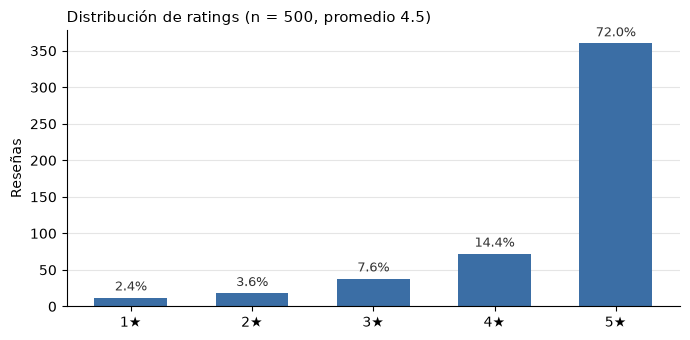

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(rating_counts.index, rating_counts.values, width=0.6, color="#3b6ea5")
ax.bar_label(bars, labels=[f"{p}%" for p in rating_pct], padding=3, fontsize=9, color="#333")
ax.set_xticks(rating_counts.index, [f"{r}★" for r in rating_counts.index])
ax.set_ylabel("Reseñas")
ax.set_title("Distribución de ratings (n = 500, promedio 4.5)", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

El promedio es exactamente **4.5** y la distribución está muy sesgada hacia las 5★. Para comparar después con el modelo, agrupamos los ratings humanos con el mismo mapeo que usaremos para las predicciones (1–2 Negativo, 3 Neutral, 4–5 Positivo).

In [7]:
def stars_to_band(stars: int) -> str:
    if stars <= 2:
        return "Negativo"
    if stars == 3:
        return "Neutral"
    return "Positivo"


human_band = df["rating"].map(stars_to_band)
(human_band.value_counts(normalize=True) * 100).round(1).reindex(["Positivo", "Neutral", "Negativo"]).to_frame("% según rating humano")

,% según rating humano
rating,
Positivo,86.4
Neutral,7.6
Negativo,6.0


Esa es la referencia: si el texto "coincidiera" perfectamente con las estrellas, el modelo debería acercarse a **86% positivo / 8% neutral / 6% negativo**. Ahora miremos el texto: longitud y contenido.

In [8]:
lengths = pd.DataFrame({
    "caracteres": df["review_text"].str.len(),
    "palabras": df["review_text"].str.split().str.len(),
})
display(lengths.describe().round(1).T)
display(lengths.assign(rating=df["rating"]).groupby("rating")["palabras"].mean().round(1).to_frame("palabras promedio"))

,count,mean,std,min,25%,50%,75%,max
caracteres,500.0,170.2,27.1,86.0,155.0,173.0,189.0,230.0
palabras,500.0,29.1,4.8,14.0,26.0,29.0,32.0,42.0


,palabras promedio
rating,
1,30.2
2,26.4
3,26.8
4,30.5
5,29.2


Reseñas cortas (14–42 palabras), muy por debajo del límite de 512 tokens de BERT, y sin diferencias de longitud relevantes entre ratings. Una pequeña muestra por rating para leerlas:

In [9]:
sample = df.groupby("rating", group_keys=False).sample(2, random_state=42)
sample[["review_id", "rating", "review_text"]]

,review_id,rating,review_text
441,442,1,Visited Harbor House Café last weekend. The coffee tasted burnt. The cashier was rude when i asked about the menu. The place felt cramped and chaotic. Not sure I'll be returning.
427,428,1,Regular customer at Harbor House Café here. The coffee tasted burnt. The staff seemed annoyed to be there. It was way too loud to hold a conversation. Disappointing experience overall.
194,195,2,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our order wrong twice. Probably won't recommend it to friends.
338,339,2,Regular customer at Harbor House Café here. The coffee tasted burnt. Nobody checked on us the entire meal. Disappointing experience overall.
479,480,3,"Visited Harbor House Café last weekend. Average sandwiches, nothing to write home about. The staff seemed annoyed to be there. Might give it another shot."
161,162,3,"Visited Harbor House Café last weekend. The menu is fine but a bit repetitive. Service was fine, nothing memorable. It's fine for a quick stop."
323,324,4,"Came to Harbor House Café for a birthday brunch. The food was absolutely delicious. We waited 25 minutes just to get water, but overall a solid experience. It's fine for a quick stop."
20,21,4,"The coffee was rich and perfectly brewed. The staff were polite but a bit slow, but overall a solid experience. This is now my go-to spot."
143,144,5,The music and decor set the perfect mood. Best brunch i've had in months. Five stars without hesitation.
136,137,5,Grabbed a quick coffee at Harbor House Café this morning. Great spot to work or catch up with friends. The team clearly cares about the customers. Five stars without hesitation.


Las reseñas parecen seguir una plantilla: una frase de apertura, una o dos sobre comida/servicio/ambiente y un cierre. Lo comprobamos partiendo cada reseña en frases.

In [10]:
sentences = (
    df.assign(sentence=df["review_text"].str.split(r"(?<=[.!?])\s+"))
      .explode("sentence")
)
sentences = sentences[sentences["sentence"].str.strip() != ""]
print(f"Frases totales: {len(sentences)}  |  frases únicas: {sentences['sentence'].nunique()}")

openings = df["review_text"].str.split(".").str[0]
print(f"Aperturas únicas: {openings.nunique()} (las 6 más comunes cubren {openings.value_counts().head(6).sum()} reseñas)")

Frases totales: 2108  |  frases únicas: 69
Aperturas únicas: 28 (las 6 más comunes cubren 433 reseñas)


Solo **69 frases únicas** en 2 108: el dataset se construyó combinando frases de un repertorio fijo. Lo que más importa para el análisis de sentimiento es que algunas reseñas mezclan una **queja de servicio** con un giro positivo al final.

In [11]:
MIXED_PATTERNS = {
    "queja + 'but overall a solid experience'": "but overall a solid experience",
    "queja + 'but honestly the food made up for it'": "but honestly the food made up for it",
}
mixed = pd.DataFrame({name: df["review_text"].str.contains(pat, regex=False)
                      for name, pat in MIXED_PATTERNS.items()})
mixed_by_rating = mixed.groupby(df["rating"]).sum()
mixed_by_rating.loc["total"] = mixed_by_rating.sum()
mixed_by_rating

,queja + 'but overall a solid experience',queja + 'but honestly the food made up for it'
rating,,
1,0,0
2,0,0
3,0,0
4,69,0
5,0,21
total,69,21


In [12]:
df[mixed.any(axis=1)].groupby("rating").head(2)[["review_id", "rating", "review_text"]]

,review_id,rating,review_text
9,10,5,"The pastries were incredible. The staff seemed annoyed to be there, but honestly the food made up for it. This is now my go-to spot."
16,17,4,"Tried Harbor House Café after seeing it recommended online. The sourdough bread alone is worth the visit. The staff were polite but a bit slow, but overall a solid experience. Five stars without hesitation."
18,19,4,"Regular customer at Harbor House Café here. The pastries were incredible. The staff were polite but a bit slow, but overall a solid experience. Might give it another shot."
21,22,5,"Fresh ingredients you can really taste. We waited 25 minutes just to get water, but honestly the food made up for it. Will definitely be back!"


**90 reseñas (18%)** son de 4–5★ pero contienen una queja concreta (esperas, personal molesto, pedidos equivocados). Para un modelo entrenado con reseñas de productos, son las candidatas naturales a **falsos negativos**.

Por último, ¿hay frases que aparecen en reseñas de **bandas** distintas (p. ej. una queja en una reseña de 3★)?

In [13]:
sent_stats = sentences.groupby("sentence")["rating"].agg(["count", "min", "max", "mean"]).round(2)
crosses_band = sent_stats["min"].map(stars_to_band) != sent_stats["max"].map(stars_to_band)
# Excluimos las aperturas neutras ("Visited Harbor House Café...") que aparecen con cualquier rating
inconsistent = sent_stats[crosses_band & ~sent_stats.index.str.contains("Harbor House")]
inconsistent.sort_values("mean")

,count,min,max,mean
sentence,,,,
The cashier was rude when i asked about the menu.,6,1,3,1.67
Nobody checked on us the entire meal.,10,1,3,1.90
Our server got our order wrong twice.,10,1,3,2.10
The staff seemed annoyed to be there.,5,1,3,2.20
"The food was decent, nothing special.",8,2,3,2.88
"Service was fine, nothing memorable.",10,2,3,2.90
The menu is fine but a bit repetitive.,11,2,3,2.91
The staff were polite but a bit slow.,15,2,3,2.93
Might give it another shot.,23,3,4,3.30


### Insights clave

1. **El promedio de 4.5★ es real**: 86% de las reseñas son de 4–5★, 8% de 3★ y 6% de 1–2★. Es la línea base contra la que compararemos el modelo.
2. **El texto es corto y limpio**: sin faltantes ni textos vacíos, y con longitudes muy por debajo del límite de BERT; no hace falta truncar ni preprocesar.
3. **El dataset es de plantilla** (69 frases únicas): los errores del modelo se repetirán en bloque, así que será fácil encontrar *patrones* de falsos negativos, no solo casos sueltos.
4. **18% de las reseñas son mixtas**: queja de servicio + cierre positivo, y aun así 4–5★. Es el punto más probable de desacuerdo entre texto y estrellas.
5. **Hay ruido en las fronteras del rating humano**: quejas como "The cashier was rude" en reseñas de 3★ y cierres tibios ("Might give it another shot") en reseñas de 4★. Algunas "discrepancias" vendrán del rating, no del modelo.

### Propuesta de limpieza

**No se necesita limpieza.** No hay faltantes, tipos incorrectos ni textos vacíos, y el modelo es *uncased*, así que no importan mayúsculas ni detalles como "i" en minúscula.

- **Duplicados (7 pares)**: se **conservan**. Tienen `review_id` distinto y el mismo rating, y el cliente entregará las 500 reseñas como un conjunto; eliminarlos cambiaría la base sobre la que se calcula el 4.5★ (y movería los porcentajes ~1 punto como máximo).
- **Texto**: se pasa al modelo tal cual. Quitar puntuación o *stopwords* le restaría contexto que el modelo sí sabe usar.

## Plan de acción y elección del modelo

**¿Por qué un modelo preentrenado?** Solo tenemos 500 reseñas y la pregunta no es predecir estrellas, sino *leer* el texto con un criterio independiente de ellas. Un modelo que ya sabe leer sentimiento nos da esa segunda opinión sin entrenar nada; entrenarlo con estos mismos ratings la contaminaría.

**Modelo: `nlptown/bert-base-multilingual-uncased-sentiment`**

- Predice **de 1 a 5 estrellas**, la misma escala que el rating humano, así que la comparación es directa.
- Es *uncased* y multilingüe: el inglés del dataset y los detalles de mayúsculas no son problema.
- **Riesgo conocido — desajuste de dominio:** se entrenó con **reseñas de productos**, y estas son de **un servicio** (personal, esperas, ambiente). Esperamos **falsos negativos**, sobre todo en el 18% de reseñas mixtas (queja + "but overall a solid experience"). Lo usamos igualmente: encontrar y explicar esos errores es parte del análisis.

**Mapeo a bandas** (el mismo para predicciones y ratings humanos):

| Estrellas | Banda |
|-----------|-------|
| 1–2 | Negativo |
| 3 | Neutral |
| 4–5 | Positivo |

**Pasos:**

1. **Inferencia:** cargar el modelo **una sola vez** con `pipeline()`, fijado a un commit concreto del Hub (no "latest"), y procesar las 500 reseñas en lotes. Guardar por reseña `pred_stars`, `pred_score` (confianza) y `sentiment_band`.
2. **Desglose vs 4.5★:** % positivo / neutral / negativo del modelo frente al 86 / 8 / 6 del rating humano, promedio de estrellas predichas frente a 4.5 y tabla cruzada rating humano × predicción.
3. **Falsos negativos:** reseñas con 4–5★ humanas y 1–2★ predichas (y desacuerdos menores, como 4–5★ → 3★). Buscar las frases que comparten y formular hipótesis sobre por qué un modelo de productos las lee mal.
4. **Revisión manual:** 15–20 reseñas estratificadas (aciertos, falsos negativos, neutrales, desacuerdos), con una nota sobre si la predicción tiene sentido.
5. **Conclusiones** en lenguaje claro para la account manager.

## Inferencia sobre las 500 reseñas

Cargamos el modelo **una sola vez**, fijado a un commit concreto del Hub para que cualquiera que clone el repo obtenga exactamente el mismo modelo. Los pesos se descargan a la caché local de Hugging Face; no se guardan en el repositorio.

In [14]:
import os

# Salida limpia: sin barras de progreso de descarga ni avisos de symlinks en Windows
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

from transformers import pipeline

MODEL_NAME = "nlptown/bert-base-multilingual-uncased-sentiment"
MODEL_REVISION = "8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d"  # commit fijado en el Hub

sentiment_clf = pipeline(
    "sentiment-analysis",
    model=MODEL_NAME,
    revision=MODEL_REVISION,
    device=-1,  # CPU
)
sentiment_clf("The coffee was rich and perfectly brewed.")

[{'label': '5 stars', 'score': 0.8150430917739868}]

El modelo devuelve etiquetas como `"5 stars"` con su confianza. Pasamos las 500 reseñas de una vez, en lotes, reutilizando el mismo `pipeline`.

In [15]:
predictions = sentiment_clf(df["review_text"].tolist(), batch_size=16, truncation=True)

results = df.assign(
    pred_stars=[int(p["label"].split()[0]) for p in predictions],
    pred_score=[round(p["score"], 4) for p in predictions],
)
results["sentiment_band"] = results["pred_stars"].map(stars_to_band)
results["rating_band"] = results["rating"].map(stars_to_band)

print(f"Reseñas con predicción: {results['pred_stars'].notna().sum()} / {len(results)}")
results.head()

Reseñas con predicción: 500 / 500


,review_id,rating,review_text,pred_stars,pred_score,sentiment_band,rating_band
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.,5,0.7170,Positivo,Positivo
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.,5,0.9822,Positivo,Positivo
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next visit.,5,0.6623,Positivo,Positivo
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.,5,0.9895,Positivo,Positivo
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.,5,0.9829,Positivo,Positivo


Las 500 reseñas tienen predicción. Ahora, la pregunta central: ¿lo que el modelo lee en el texto coincide con el 4.5★?

## Desglose de sentimiento vs promedio de 4.5★

In [16]:
BANDS = ["Positivo", "Neutral", "Negativo"]
breakdown = pd.DataFrame({
    "% modelo (texto)": results["sentiment_band"].value_counts(normalize=True),
    "% rating humano": results["rating_band"].value_counts(normalize=True),
}).reindex(BANDS).fillna(0).mul(100).round(1)
breakdown["diferencia (pp)"] = (breakdown["% modelo (texto)"] - breakdown["% rating humano"]).round(1)
display(breakdown)

print(f"Promedio de estrellas — rating humano: {results['rating'].mean():.2f}  |  modelo: {results['pred_stars'].mean():.2f}")

,% modelo (texto),% rating humano,diferencia (pp)
Positivo,82.4,86.4,-4.0
Neutral,8.2,7.6,0.6
Negativo,9.4,6.0,3.4


Promedio de estrellas — rating humano: 4.50  |  modelo: 4.40


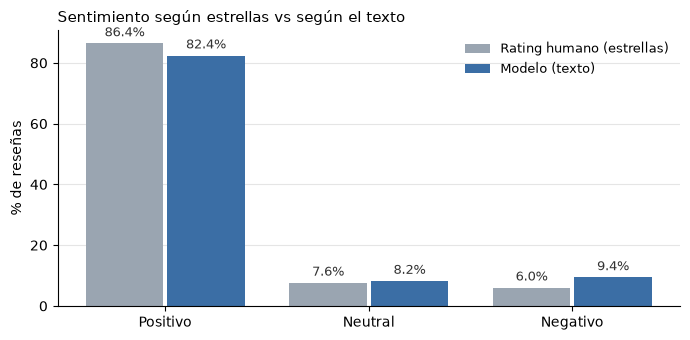

In [17]:
import numpy as np

fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(len(BANDS))
w = 0.38
b1 = ax.bar(x - w / 2 - 0.01, breakdown["% rating humano"], w, color="#9aa5b1", label="Rating humano (estrellas)")
b2 = ax.bar(x + w / 2 + 0.01, breakdown["% modelo (texto)"], w, color="#3b6ea5", label="Modelo (texto)")
for bars in (b1, b2):
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9, color="#333")
ax.set_xticks(x, BANDS)
ax.set_ylabel("% de reseñas")
ax.set_title("Sentimiento según estrellas vs según el texto", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

Para ver **dónde** está la diferencia, cruzamos el rating humano con las estrellas que predijo el modelo:

In [18]:
crosstab = pd.crosstab(results["rating"], results["pred_stars"], margins=True, margins_name="total")
crosstab.index.name, crosstab.columns.name = "rating humano", "estrellas predichas"
crosstab

estrellas predichas,1,2,3,4,5,total
rating humano,,,,,,
1,3,9,0,0,0,12
2,7,9,2,0,0,18
3,0,3,35,0,0,38
4,1,0,3,47,21,72
5,11,4,1,9,335,360
total,22,25,41,56,356,500


In [19]:
band_agreement = (results["sentiment_band"] == results["rating_band"]).mean() * 100
exact_agreement = (results["pred_stars"] == results["rating"]).mean() * 100
print(f"Coincidencia de banda: {band_agreement:.1f}%  |  coincidencia exacta de estrellas: {exact_agreement:.1f}%")
pd.crosstab(results["rating_band"], results["sentiment_band"]).reindex(index=BANDS, columns=BANDS, fill_value=0)

Coincidencia de banda: 95.0%  |  coincidencia exacta de estrellas: 85.8%


sentiment_band,Positivo,Neutral,Negativo
rating_band,,,
Positivo,412,4,16
Neutral,0,35,3
Negativo,0,2,28


### Lectura del desglose

- **En general, el texto sí respalda el 4.5★.** El modelo lee **82.4% positivo / 8.2% neutral / 9.4% negativo**, frente al 86.4 / 7.6 / 6.0 de las estrellas, y su promedio es **4.40★** frente a 4.50. Coinciden en la banda **95% de las veces**.
- **La diferencia está casi toda en un punto:** el modelo pasa **16 reseñas de 4–5★ a 1–2★** (15 de ellas de 5★). Eso explica los ~4 puntos que pierde "Positivo" y los ~3 que gana "Negativo". Son los **falsos negativos** que analizamos a continuación.
- **Lo contrario no ocurre:** ninguna reseña de 1–2★ se lee como positiva. El modelo no "infla" el sentimiento; si se equivoca, es hacia abajo.
- **En los ratings bajos el desacuerdo es menor:** 5 reseñas negativas o neutrales cambian entre esas dos bandas, coherente con el ruido de frontera que vimos en el EDA.

## Falsos negativos

Definimos **falso negativo** como una reseña con **4–5★ humanas** que el modelo predice con **1–2★**.

In [20]:
is_fn = (results["rating"] >= 4) & (results["pred_stars"] <= 2)
false_negatives = results[is_fn]
correct_positives = results[(results["rating"] >= 4) & (results["pred_stars"] >= 4)]

print(f"Falsos negativos: {len(false_negatives)} de {(results['rating'] >= 4).sum()} reseñas de 4–5★")
print(f"Confianza media — falsos negativos: {false_negatives['pred_score'].mean():.2f}  |  positivos acertados: {correct_positives['pred_score'].mean():.2f}")
false_negatives[["review_id", "rating", "pred_stars", "pred_score", "review_text"]]

Falsos negativos: 16 de 432 reseñas de 4–5★
Confianza media — falsos negativos: 0.38  |  positivos acertados: 0.74


,review_id,rating,pred_stars,pred_score,review_text
13,14,4,1,0.4443,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
14,15,5,1,0.3893,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit."
72,73,5,1,0.2679,Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
86,87,5,1,0.3247,Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!
137,138,5,2,0.2751,"Tried Harbor House Café after seeing it recommended online. They went out of their way to accommodate my allergy. The place has such a cozy, welcoming vibe. Already planning my next visit."
199,200,5,2,0.3685,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.
203,204,5,1,0.3492,"Came to Harbor House Café for a birthday brunch. Every dish was bursting with flavor. The cashier was rude when i asked about the menu, but honestly the food made up for it. Already planning my next visit."
253,254,5,1,0.3641,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
269,270,5,1,0.4091,Stopped by Harbor House Café for the first time. Our server remembered our names by the second visit. Every dish was bursting with flavor. Great value for what you get. Will definitely be back!
321,322,5,1,0.6077,"Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Will definitely be back!"


Leídas por un humano, **las 16 son claramente positivas** y el modelo las clasifica con poca confianza (~0.38 frente a ~0.74 en los aciertos).

En el EDA esperábamos que los errores vinieran de las reseñas mixtas (queja + cierre positivo). Lo comprobamos:

In [21]:
is_mixed = results["review_text"].str.contains("but overall a solid experience|but honestly the food made up for it")
print(f"Reseñas mixtas entre los falsos negativos: {is_mixed[is_fn].sum()} de {is_fn.sum()}")
print(f"Reseñas mixtas de 4–5★ que el modelo sí lee como positivas: {(is_mixed & (results['rating'] >= 4) & (results['pred_stars'] >= 4)).sum()} de {(is_mixed & (results['rating'] >= 4)).sum()}")

Reseñas mixtas entre los falsos negativos: 2 de 16
Reseñas mixtas de 4–5★ que el modelo sí lee como positivas: 84 de 90


**La hipótesis del EDA no se cumple:** el modelo maneja bien las reseñas mixtas (84 de 90 positivas) y solo 2 de los 16 errores son mixtos. El problema está en otro lado. Como el dataset es de plantilla, podemos ver qué frases se repiten en los errores: para cada frase de las reseñas de 4–5★, ¿qué proporción de las reseñas que la contienen acaba como falso negativo?

In [22]:
positive_reviews = results[results["rating"] >= 4].assign(is_fn=is_fn)
pos_sentences = (
    positive_reviews.assign(sentence=positive_reviews["review_text"].str.split(r"(?<=[.!?])\s+"))
    .explode("sentence")
)
phrase_fn = (
    pos_sentences.groupby("sentence")["is_fn"]
    .agg(reseñas="size", falsos_negativos="sum")
    .assign(tasa_fn=lambda t: (t["falsos_negativos"] / t["reseñas"]).round(2))
)
baseline_rate = is_fn.sum() / len(positive_reviews)
print(f"Tasa base de falsos negativos en reseñas de 4–5★: {baseline_rate:.2f}")
phrase_fn[phrase_fn["falsos_negativos"] >= 3].sort_values("tasa_fn", ascending=False)

Tasa base de falsos negativos en reseñas de 4–5★: 0.04


,reseñas,falsos_negativos,tasa_fn
sentence,,,
Every dish was bursting with flavor.,41,12,0.29
Already planning my next visit.,75,11,0.15
They went out of their way to accommodate my allergy.,38,4,0.11
Stopped by Harbor House Café for the first time.,61,6,0.10
Tried Harbor House Café after seeing it recommended online.,68,6,0.09
The team clearly cares about the customers.,49,3,0.06
Service was fast and friendly.,56,3,0.05
Will definitely be back!,85,4,0.05


Destacan tres frases: **"Every dish was bursting with flavor."** (12 de los 16 errores; casi 1 de cada 3 reseñas que la contienen falla), **"Already planning my next visit."** (11) y **"They went out of their way to accommodate my allergy."** (4). Para ver si el modelo las malinterpreta por sí mismas, le pasamos **cada frase sola**, reutilizando el mismo `pipeline` ya cargado:

In [23]:
fn_sentences = pos_sentences.loc[pos_sentences["is_fn"], "sentence"].unique().tolist()
isolated = sentiment_clf(fn_sentences, batch_size=16)
isolated_df = pd.DataFrame({
    "frase": fn_sentences,
    "estrellas (frase sola)": [int(p["label"].split()[0]) for p in isolated],
    "confianza": [round(p["score"], 2) for p in isolated],
}).sort_values("estrellas (frase sola)")
isolated_df.head(8)

,frase,estrellas (frase sola),confianza
0,Tried Harbor House Café after seeing it recommended online.,1,0.45
1,Every dish was bursting with flavor.,1,0.67
5,Stopped by Harbor House Café for the first time.,1,0.62
9,They went out of their way to accommodate my allergy.,1,0.44
13,"The cashier was rude when i asked about the menu, but honestly the food made up for it.",3,0.35
17,"The staff seemed annoyed to be there, but honestly the food made up for it.",3,0.42
6,Service was fast and friendly.,4,0.45
8,The seasonal menu never disappoints.,4,0.47


Frases que cualquier persona lee como elogio, o como simple contexto, el modelo las puntúa con **1★** al leerlas solas. Última prueba (contrafactual): quitamos las frases sospechosas de los 16 falsos negativos y volvemos a predecir.

In [24]:
SUSPECT_PHRASES = [
    "Every dish was bursting with flavor.",
    "Already planning my next visit.",
    "They went out of their way to accommodate my allergy.",
]

def remove_phrases(texts: pd.Series, phrases: list[str]) -> pd.Series:
    for phrase in phrases:
        texts = texts.str.replace(phrase, "", regex=False)
    return texts.str.replace(r"\s+", " ", regex=True).str.strip()

scenarios = {f"sin '{p}'": [p] for p in SUSPECT_PHRASES}
scenarios["sin las tres"] = SUSPECT_PHRASES

rows = []
for name, phrases in scenarios.items():
    edited = remove_phrases(false_negatives["review_text"], phrases).tolist()
    stars = [int(p["label"].split()[0]) for p in sentiment_clf(edited, batch_size=16)]
    rows.append({"escenario": name, "pasan a positivo (4–5★)": sum(s >= 4 for s in stars), "de": len(stars)})
pd.DataFrame(rows)

,escenario,pasan a positivo (4–5★),de
0,sin 'Every dish was bursting with flavor.',12,16
1,sin 'Already planning my next visit.',1,16
2,sin 'They went out of their way to accommodate my allergy.',4,16
3,sin las tres,16,16


Además de los 16 falsos negativos, hay **4 reseñas de 4–5★ que el modelo deja en neutral**. Son casos más discutibles: tres combinan una frase tibia ("Service was fine, nothing memorable") con un cierre positivo, y una mezcla una espera de 25 minutos con "the food made up for it".

In [25]:
results[(results["rating"] >= 4) & (results["pred_stars"] == 3)][["review_id", "rating", "pred_stars", "pred_score", "review_text"]]

,review_id,rating,pred_stars,pred_score,review_text
146,147,4,3,0.4790,"Stopped by Harbor House Café for the first time. The seasonal menu never disappoints. Service was fine, nothing memorable, but overall a solid experience. Might give it another shot."
252,253,4,3,0.2553,"Stopped by Harbor House Café for the first time. Every dish was bursting with flavor. Average service, no complaints, but overall a solid experience. This is now my go-to spot."
463,464,4,3,0.4725,"Regular customer at Harbor House Café here. Every dish was bursting with flavor. Service was fine, nothing memorable, but overall a solid experience. Already planning my next visit."
476,477,5,3,0.2709,"Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. We waited 25 minutes just to get water, but honestly the food made up for it. Already planning my next visit."


### Patrones e hipótesis

1. **Elogios con vocabulario de "producto defectuoso".** *"bursting with flavor"*: en reseñas de productos, *bursting* suele aparecer en quejas (envases que revientan, costuras que se abren). Quitar solo esta frase rescata **12 de los 16** errores.
2. **Hablar de alergias = queja en el mundo de productos.** *"accommodate my allergy"* es un elogio al personal, pero en Amazon "allergy" casi siempre acompaña a una reacción adversa al producto.
3. **Frases de contexto de servicio que el modelo no sabe leer.** *"Stopped by … for the first time"* o *"Tried … after seeing it recommended online"* se puntúan con 1★ solas: en reseñas de productos, "lo compré por recomendación" suele ser el inicio de una decepción.
4. **"Already planning my next visit" no es negativa por sí sola**, pero acompaña a las anteriores en 11 de los 16 errores. Al quitar las tres frases, **los 16** pasan a positivo.
5. **Las quejas de servicio no son el problema.** Contra lo que esperábamos, el modelo lee bien las reseñas mixtas: el desajuste de dominio está en **cómo se expresan los elogios** en un servicio, no en las críticas.

**Conclusión de la sección:** los 16 errores son del **modelo**, no de los clientes. Son reseñas positivas que el modelo malinterpreta porque aprendió sentimiento en reseñas de productos.

## Revisión manual (18 reseñas)

Las métricas dicen *cuánto* coinciden modelo y estrellas, pero no si la predicción **tiene sentido leyendo el texto**. Tomamos una muestra estratificada (semilla fija, para que siempre salgan las mismas reseñas) de cinco grupos disjuntos y la leímos una por una.

In [26]:
pos_ok = (results["rating"] >= 4) & (results["pred_stars"] >= 4)
pos_to_neutral = (results["rating"] >= 4) & (results["pred_stars"] == 3)
neutral = ((results["rating"] == 3) | (results["pred_stars"] == 3)) & ~pos_to_neutral
negative = (results["rating"] <= 2) & (results["pred_stars"] <= 2)

SAMPLE_PLAN = {
    "Positivo acertado": (pos_ok, 5),
    "Falso negativo": (is_fn, 4),
    "Neutral (humano o modelo)": (neutral, 4),
    "Negativo": (negative, 3),
    "4–5★ → neutral": (pos_to_neutral, 2),
}
manual_sample = pd.concat(
    results[mask].sample(n, random_state=42).assign(grupo=group)
    for group, (mask, n) in SAMPLE_PLAN.items()
)
assert manual_sample["review_id"].is_unique
print(f"Reseñas en la muestra: {len(manual_sample)}")

Reseñas en la muestra: 18


Notas de la lectura manual. **Veredicto:** *Correcta* (la banda predicha es la que un humano asignaría), *Incorrecta* o *Discutible* (el texto admite las dos lecturas).

In [27]:
MANUAL_NOTES = {
    # Positivos acertados
    333: ("Correcta", "Mezcla 'Best brunch i've had in months' con frases tibias; positivo es razonable, aunque neutral también sería defendible."),
    67:  ("Correcta", "Cuatro elogios claros (equipo, café, precio, volverá)."),
    292: ("Correcta", "Positiva sin matices. Incluye 'Already planning my next visit' y aun así acierta: la frase no es negativa por sí sola."),
    42:  ("Correcta", "Café excelente y servicio lento compensado ('overall a solid experience'); 4★ positivo encaja."),
    351: ("Correcta", "Claramente positiva, pero con confianza baja (0.34): la apertura 'Stopped by... for the first time' resta seguridad."),
    # Falsos negativos
    14:  ("Incorrecta", "100% elogios. Contiene 'bursting with flavor' y 'recommended online', dos de las frases que el modelo lee como 1★."),
    15:  ("Incorrecta", "Tres frases positivas; 'bursting with flavor' arrastra la predicción a 1★."),
    200: ("Incorrecta", "Ambiente, comida y ganas de volver: positiva. Mismo patrón ('first time' + 'bursting')."),
    474: ("Incorrecta", "Termina con 'This is now my go-to spot'; inequívocamente positiva."),
    # Neutrales
    239: ("Correcta", "Todo tibio ('fine but repetitive', 'polite but slow'): neutral."),
    215: ("Discutible", "'Nobody checked on us the entire meal' es una queja real; el 3★ humano es generoso y el 2★ del modelo es defendible."),
    192: ("Discutible", "El cuerpo es tibio ('decent', 'fine') y solo el cierre es negativo; el neutral del modelo es tan razonable como el 2★ humano."),
    345: ("Correcta", "Comida promedio, servicio lento, 'fine for a quick stop': neutral."),
    # Negativos
    123: ("Correcta", "Cuatro quejas (porciones, espera, limpieza, decepción). El modelo dice 2★ y no 1★, pero la banda es correcta."),
    442: ("Correcta", "Café quemado, cajero grosero, local caótico: negativa."),
    115: ("Correcta", "Pastelería rancia y espera de 25 minutos: negativa."),
    # 4–5★ → neutral
    253: ("Incorrecta", "'This is now my go-to spot' + 'bursting with flavor': positiva. El servicio 'average' no la vuelve neutral."),
    477: ("Discutible", "Espera de 25 minutos compensada por la comida y planea volver: positiva para un humano, pero se entiende el neutral."),
}

assert set(MANUAL_NOTES) == set(manual_sample["review_id"]), "La muestra cambió: revisar las notas"
manual_review = manual_sample.assign(
    veredicto=manual_sample["review_id"].map(lambda i: MANUAL_NOTES[i][0]),
    nota_manual=manual_sample["review_id"].map(lambda i: MANUAL_NOTES[i][1]),
)[["grupo", "review_id", "rating", "pred_stars", "pred_score", "review_text", "veredicto", "nota_manual"]]
manual_review

,grupo,review_id,rating,pred_stars,pred_score,review_text,veredicto,nota_manual
332,Positivo acertado,333,4,4,0.6343,"Came to Harbor House Café for a birthday brunch. Best brunch i've had in months. Average service, no complaints, but overall a solid experience. Wouldn't go out of my way, but wouldn't avoid it either.",Correcta,"Mezcla 'Best brunch i've had in months' con frases tibias; positivo es razonable, aunque neutral también sería defendible."
66,Positivo acertado,67,5,5,0.5827,The team clearly cares about the customers. The coffee was rich and perfectly brewed. Reasonably priced for the quality. Will definitely be back!,Correcta,"Cuatro elogios claros (equipo, café, precio, volverá)."
291,Positivo acertado,292,5,5,0.5905,Grabbed a quick coffee at Harbor House Café this morning. The music and decor set the perfect mood. Our server remembered our names by the second visit. Already planning my next visit.,Correcta,Positiva sin matices. Incluye 'Already planning my next visit' y aun así acierta: la frase no es negativa por sí sola.
41,Positivo acertado,42,4,4,0.7713,"The coffee was rich and perfectly brewed. The staff were polite but a bit slow, but overall a solid experience. It's fine for a quick stop.",Correcta,Café excelente y servicio lento compensado ('overall a solid experience'); 4★ positivo encaja.
350,Positivo acertado,351,5,5,0.3399,"Stopped by Harbor House Café for the first time. Service was fast and friendly. The place has such a cozy, welcoming vibe. Will definitely be back!",Correcta,"Claramente positiva, pero con confianza baja (0.34): la apertura 'Stopped by... for the first time' resta seguridad."
13,Falso negativo,14,4,1,0.4443,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.,Incorrecta,"100% elogios. Contiene 'bursting with flavor' y 'recommended online', dos de las frases que el modelo lee como 1★."
14,Falso negativo,15,5,1,0.3893,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit.",Incorrecta,Tres frases positivas; 'bursting with flavor' arrastra la predicción a 1★.
199,Falso negativo,200,5,2,0.3685,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.,Incorrecta,"Ambiente, comida y ganas de volver: positiva. Mismo patrón ('first time' + 'bursting')."
473,Falso negativo,474,5,1,0.4817,Stopped by Harbor House Café for the first time. Every dish was bursting with flavor. Service was fast and friendly. This is now my go-to spot.,Incorrecta,Termina con 'This is now my go-to spot'; inequívocamente positiva.
238,Neutral (humano o modelo),239,3,3,0.5241,Came to Harbor House Café for a birthday brunch. The menu is fine but a bit repetitive. The staff were polite but a bit slow. It's fine for a quick stop.,Correcta,"Todo tibio ('fine but repetitive', 'polite but slow'): neutral."


In [28]:
manual_review.groupby("grupo", sort=False)["veredicto"].value_counts().unstack(fill_value=0)

veredicto,Correcta,Incorrecta,Discutible
grupo,,,
Positivo acertado,5,0,0
Falso negativo,0,4,0
Neutral (humano o modelo),2,0,2
Negativo,3,0,0
4–5★ → neutral,0,1,1


### Qué nos deja la revisión manual

- **10 correctas, 5 incorrectas y 3 discutibles** (la muestra sobrerrepresenta a propósito los casos difíciles; en el total, la coincidencia de banda es del 95%).
- **Las 5 incorrectas son reseñas positivas leídas a la baja, y todas contienen *"bursting with flavor"*** (algunas también *"for the first time"* o *"recommended online"*). La lectura humana confirma el patrón de la sección anterior.
- **Las discutibles están en la frontera neutral/negativa o en reseñas mixtas**, donde ni las estrellas humanas son del todo consistentes (lo vimos en el EDA). No las contamos como fallo del modelo.
- **En los extremos el modelo es fiable:** las reseñas claramente negativas y las positivas sin esas frases salen bien.

## Conclusiones

Antes del resumen, un último cálculo: ¿cómo quedaría la distribución del texto si corregimos los 16 falsos negativos, que la lectura manual confirmó como positivos?

In [29]:
corrected_band = results["sentiment_band"].mask(is_fn, "Positivo")
summary = pd.DataFrame({
    "Rating humano": results["rating_band"].value_counts(normalize=True),
    "Modelo": results["sentiment_band"].value_counts(normalize=True),
    "Modelo corrigiendo los 16 FN": corrected_band.value_counts(normalize=True),
}).reindex(BANDS).fillna(0).mul(100).round(1)
summary

,Rating humano,Modelo,Modelo corrigiendo los 16 FN
Positivo,86.4,82.4,85.6
Neutral,7.6,8.2,8.2
Negativo,6.0,9.4,6.2


### Para la account manager

**1. Sí: lo que escriben los clientes respalda el 4.5★.** Un modelo de lectura de sentimiento clasifica el **82% de las reseñas como positivas, 8% como neutrales y 9% como negativas**. Las estrellas dicen 86 / 8 / 6. Ambos coinciden en el **95%** de las reseñas.

**2. La diferencia (unos 4 puntos menos de positivas) no viene de los clientes, sino del modelo.** Se concentra en 16 reseñas de 4–5★ que el modelo lee como negativas. Al leerlas, las 16 son claramente elogiosas: el modelo se confunde con expresiones como *"every dish was bursting with flavor"* o *"they accommodated my allergy"*, porque aprendió con reseñas de productos, donde esas palabras suelen acompañar a quejas. Corrigiendo esos 16 casos, el texto queda en **85.6% positivo**, prácticamente igual que las estrellas.

**3. Qué decirle al cliente:**
- Unas **9 de cada 10 reseñas son positivas**, con elogios a la comida, el ambiente y el trato del personal.
- Las quejas reales son pocas (**~6%**) y concretas: café quemado o platos fríos, esperas largas y trato descortés de algunos empleados.
- **1 de cada 5 reseñas positivas** (90 de 432) menciona un problema de servicio (esperas, personal lento o desatento) aunque el cliente termine contento: es la oportunidad de mejora más clara.

**4. Advertencia para WeLoveReviews:** este modelo **subestima los elogios típicos de negocios de servicios** (restaurantes, cafés). Para este cliente no cambia la conclusión, pero antes de usarlo con otros conviene validar un modelo más adecuado (ver el addendum).

## Addendum: ¿hay un modelo mejor para este cliente?

Probamos `tabularisai/multilingual-sentiment-analysis` sobre las mismas 500 reseñas, con las mismas reglas: cargado una sola vez y fijado a un commit del Hub. Devuelve 5 clases en lugar de estrellas, que agrupamos en las mismas tres bandas.

In [30]:
ALT_MODEL_NAME = "tabularisai/multilingual-sentiment-analysis"
ALT_MODEL_REVISION = "eea032081f8d247b4303ef3565e7cec1b6f201c9"  # commit fijado en el Hub

alt_clf = pipeline("sentiment-analysis", model=ALT_MODEL_NAME, revision=ALT_MODEL_REVISION, device=-1)
print(alt_clf.model.config.id2label)

ALT_LABEL_TO_BAND = {
    "Very Negative": "Negativo", "Negative": "Negativo",
    "Neutral": "Neutral",
    "Positive": "Positivo", "Very Positive": "Positivo",
}
alt_predictions = alt_clf(results["review_text"].tolist(), batch_size=16, truncation=True)
results["alt_label"] = [p["label"] for p in alt_predictions]
results["alt_score"] = [round(p["score"], 4) for p in alt_predictions]
results["alt_band"] = results["alt_label"].map(ALT_LABEL_TO_BAND)
assert results["alt_band"].notna().all()

{0: 'Very Negative', 1: 'Negative', 2: 'Neutral', 3: 'Positive', 4: 'Very Positive'}


Comparamos los dos modelos con las mismas métricas:

In [31]:
def model_metrics(band: pd.Series) -> dict:
    positive = results["rating"] >= 4
    return {
        "% positivo": round((band == "Positivo").mean() * 100, 1),
        "% neutral": round((band == "Neutral").mean() * 100, 1),
        "% negativo": round((band == "Negativo").mean() * 100, 1),
        "coincidencia de banda (%)": round((band == results["rating_band"]).mean() * 100, 1),
        "falsos negativos (4–5★ → Negativo)": int((positive & (band == "Negativo")).sum()),
        "4–5★ → Neutral": int((positive & (band == "Neutral")).sum()),
        "3★ detectadas como Neutral": f"{int(((results['rating'] == 3) & (band == 'Neutral')).sum())} de {(results['rating'] == 3).sum()}",
    }

comparison = pd.DataFrame({
    "Rating humano": model_metrics(results["rating_band"]),
    "nlptown": model_metrics(results["sentiment_band"]),
    "tabularisai": model_metrics(results["alt_band"]),
})
comparison

,Rating humano,nlptown,tabularisai
% positivo,86.4,82.4,88.8
% neutral,7.6,8.2,2.2
% negativo,6.0,9.4,9.0
coincidencia de banda (%),100.0,95.0,90.6
falsos negativos (4–5★ → Negativo),0,16,7
4–5★ → Neutral,0,4,6
3★ detectadas como Neutral,38 de 38,35 de 38,5 de 38


In [32]:
pd.crosstab(results["rating_band"], results["alt_band"]).reindex(index=BANDS, columns=BANDS, fill_value=0)

alt_band,Positivo,Neutral,Negativo
rating_band,,,
Positivo,419,6,7
Neutral,24,5,9
Negativo,1,0,29


`tabularisai` reduce los falsos negativos a menos de la mitad, pero **casi no reconoce el neutral**: la mayoría de las reseñas de 3★ (tibias, del tipo "It's fine for a quick stop") las lee como positivas, y por eso su coincidencia global es menor. ¿Qué falsos negativos le quedan?

In [33]:
alt_fn = (results["rating"] >= 4) & (results["alt_band"] == "Negativo")
print(f"Falsos negativos de tabularisai: {alt_fn.sum()}  |  compartidos con nlptown: {(alt_fn & is_fn).sum()}")
results.loc[alt_fn, ["review_id", "rating", "alt_label", "alt_score", "pred_stars", "review_text"]]

Falsos negativos de tabularisai: 7  |  compartidos con nlptown: 1


,review_id,rating,alt_label,alt_score,pred_stars,review_text
138,139,5,Negative,0.4994,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. They went out of their way to accommodate my allergy. Five stars without hesitation.
219,220,5,Negative,0.4731,5,Visited Harbor House Café last weekend. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. This is now my go-to spot.
230,231,5,Negative,0.4662,5,They went out of their way to accommodate my allergy. The seasonal menu never disappoints. Great value for what you get. This is now my go-to spot.
253,254,5,Negative,0.6090,1,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
289,290,5,Negative,0.4001,5,Grabbed a quick coffee at Harbor House Café this morning. Best brunch i've had in months. They went out of their way to accommodate my allergy. Five stars without hesitation.
351,352,5,Very Negative,0.4740,5,They went out of their way to accommodate my allergy. The seasonal menu never disappoints. Great value for what you get. Five stars without hesitation.
414,415,5,Negative,0.3796,5,Came to Harbor House Café for a birthday brunch. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. This is now my go-to spot.


In [34]:
suspects = SUSPECT_PHRASES + [
    "Stopped by Harbor House Café for the first time.",
    "Tried Harbor House Café after seeing it recommended online.",
]
pd.DataFrame({
    "frase": suspects,
    "nlptown": [p["label"] for p in sentiment_clf(suspects)],
    "tabularisai": [p["label"] for p in alt_clf(suspects)],
})

,frase,nlptown,tabularisai
0,Every dish was bursting with flavor.,1 star,Neutral
1,Already planning my next visit.,5 stars,Neutral
2,They went out of their way to accommodate my allergy.,1 star,Negative
3,Stopped by Harbor House Café for the first time.,1 star,Neutral
4,Tried Harbor House Café after seeing it recommended online.,1 star,Neutral


### Recomendación

| | nlptown | tabularisai |
|---|---|---|
| Falsos negativos | 16 | **7** |
| Detecta reseñas neutrales (3★) | **35 de 38** | 5 de 38 |
| Coincidencia de banda con las estrellas | **95.0%** | 90.6% |

- **`tabularisai` lee mejor los elogios de servicio:** ya no se confunde con *"bursting with flavor"* ni con las frases de contexto (*"for the first time"*, *"recommended online"*), que pasan a neutral. Sus 7 falsos negativos tienen **una sola causa**: todos contienen *"accommodate my allergy"*, que este modelo también lee como queja, y solo uno coincide con los de `nlptown`.
- **Pero pierde el matiz neutral:** casi todas las reseñas tibias pasan a "positivo" o "negativo". Para la pregunta de la account manager (cuántas reseñas son positivas, neutrales o negativas) eso es un problema igual de serio que los falsos negativos.

**Recomendación: no cambiar a `tabularisai` para este cliente.** Ninguno de los dos modelos es claramente superior: cambiaríamos 9 falsos negativos menos por perder casi todo el neutral. `nlptown` sigue siendo la mejor opción para este reporte, con la corrección documentada de sus 16 falsos negativos. Si WeLoveReviews va a analizar con frecuencia reseñas de restaurantes y servicios, lo recomendable es evaluar un modelo entrenado con **reseñas de servicios** (tipo Yelp o TripAdvisor) usando este mismo notebook como banco de pruebas: los 16 + 7 falsos negativos documentados aquí son un buen set de validación.